## Background Problem 

Pelaksanaan direct marketing campaign yang dilakukan oleh bank seringkali memakan banyak biaya dan effort tim marketing dan telemarketing. Hal ini biasa disebabkan oleh kurangnya pre-screening sebelum campaign dieksekusi sehingga banyak leads atau nasabah yang sebetulnya tidak tertarik juga menjadi target dalam campaign tersebut.

Banyak institusi bank mengalami kesulitan dalam mengidentifikasi leads yang memiliki potensi tinggi untuk menerima tawaran deposit berjangka (term deposit) sehingga menyebabkan cost marketing yang tinggi dan juga conversion yang rendah.

Maka dari itu model prediksi ini dibuat untuk membantu tim marketing dalam menentukan profil nasabah mana yang bisa dihubungi lebih lanjut untuk ditawarkan produk deposit berjangka. Project ini bertujuan untuk mencari model algoritma classification terbaik dengan melakukan percobaan ke berbagai jenis algoritma seperti KNN, SVM, Decision Tree, Random Forest dan XGBoost.

Model akan di-training menggunakan dataset dari penelitian Sérgio Moro, P. Cortez, dan P. Rita pada tahun 2014 yang diunduh dari UCI Machine Learning Repository. Dataset ini memiliki total 45.211 baris dan 17 kolom
## Import Libraries

In [252]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
from utils import cardinality
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.pipeline import make_pipeline
from feature_engine.outliers import Winsorizer
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score, RandomizedSearchCV
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay, confusion_matrix

## Data Loading

In [253]:
# read dataset
df = pd.read_csv('bank-full.csv', sep=';')

# tampilkan 5 rows pertama
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no


- Seperti yang disebut juga sebelumnya, dataset ini memiliki 45211 baris dan 17 kolom. Terdapat 10 kolom kategorikal dan 7 kolom numerikal, dengan salah satu kolom y yang merupakan kolom target. Kolom y di sini memiliki makna apakah leads pada akhirnya convert atau tidak. Maka dari itu kolom ini perlu diperbarui namanya

In [254]:
# rename kolom target
df = df.rename(columns={'y':'subscribe'})

# tampilkan summary dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  subscribe  45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [255]:
# cek duplicate
print(df.duplicated().sum())

0


- Pada info di atas terlihat bahwa semua kolom sudah sesuai data type-nya.
- Dataset ini juga tidak memiliki duplicate sehingga tidak perlu di-drop lagi.

## EDA

In [256]:
# copy dataset khusus EDA
eda = df.copy()

### Metode contact yang paling sering digunakan
Karena terdapat informasi kategori metode kontak ketika menghubungi nasabah, maka kita akan melihat metode apa yang paling sering digunakan untuk menghubungi nasabah.

<Axes: ylabel='count'>

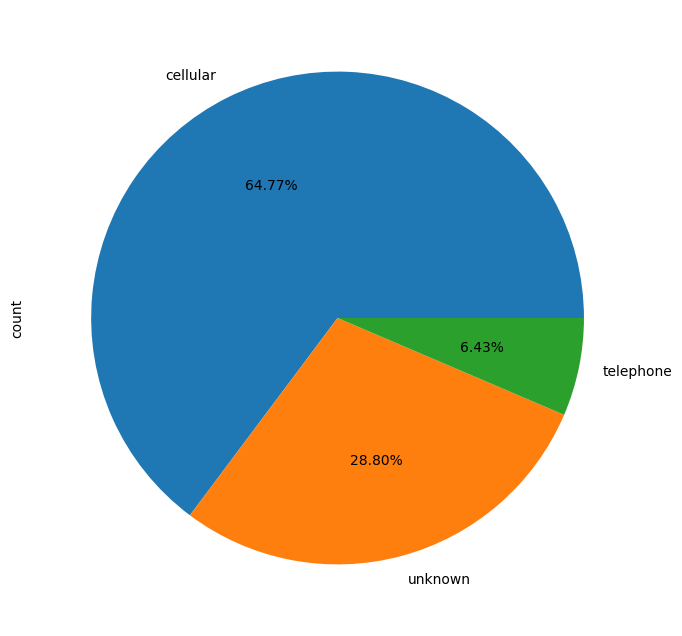

In [257]:
# buat base figure
fig, ax = plt.subplots(figsize=(12,8))

# buat piechart
eda['contact'].value_counts().plot(kind='pie', autopct="%.2f%%", ax=ax)


Secara keseluruhan, terlihat bahwa metode yang paling sering digunakan untuk menghubungi nasabah adalah dengan menggunakan cellphone dengan porsi sebanyak 64.77% terbesar kedua yaitu unknown sebesar 28.80% dan paling jarang adalah telephone sebanyak 6.43%. Mengingat teknologi telepon biasa sudah mulai banyak ditinggalkan, maka  wajar terjadi pada dataset ini di mana cellular atau telepon genggam menjadi metode komunikasi yang paling banyak digunakan saat ini.

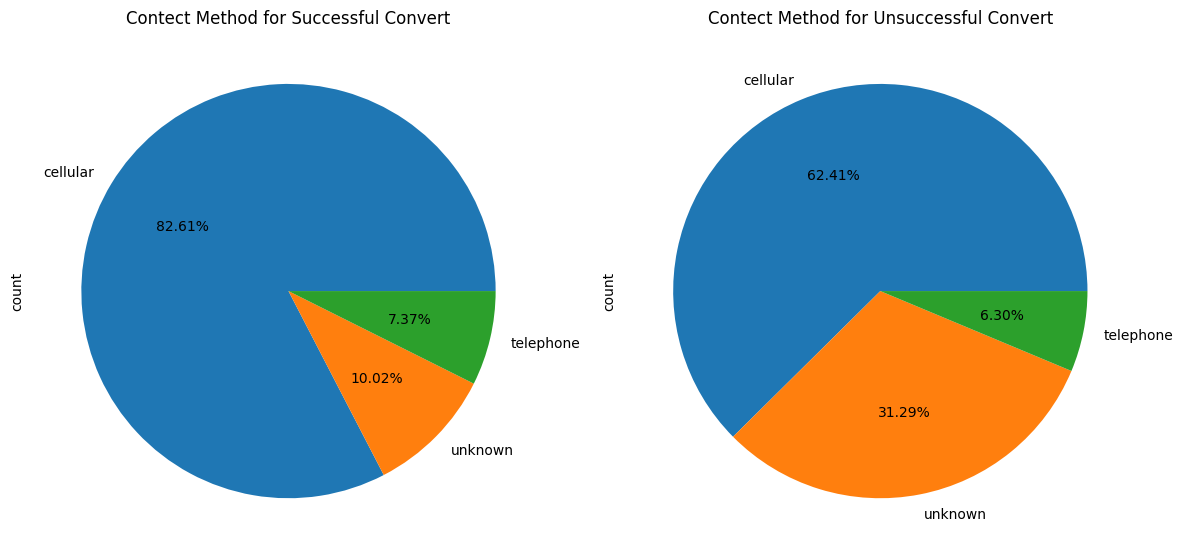

In [258]:
# slicing antara yang convert dan tidak
eda_yes = eda[eda['subscribe'] == 'yes']
eda_no = eda[eda['subscribe'] == 'no'] 

# buat pie chart
fig, ax = plt.subplots(1, 2, figsize=(12,8))
eda_yes['contact'].value_counts().plot(kind='pie', autopct="%.2f%%", ax=ax[0])
eda_no['contact'].value_counts().plot(kind='pie', autopct="%.2f%%", ax=ax[1])
ax[0].set_title('Contect Method for Successful Convert')
ax[1].set_title('Contect Method for Unsuccessful Convert')

# show plot
plt.tight_layout()
plt.show()

Dari hasil pie chart di atas, sekarang terlihat pembagiannya antara data leads yang convert maupun yang tidak.

Untuk leads yang convert terlihat bahwa metode yang paling mendominasi adalah menggunakan cellular. Porsinya mencapai 82.61% di mana angka ini sudah menjadi mayoritas. 

Sedangkan untuk leads yang tidak convert, terlihat bahwa metode yang paling banyak juga cellular sebesar 62.41%, kemudian diikuti oleh metode unknown sebanyak 31.29%, dan telephone tetap menjadi yang paling kecil.

Visualisasi data ini menunjukkan kalau metode cellular merupakan metode yang paling banyak membawa successful conversion. Maka tim telemarketing bisa melakukan optimasi dengan berfokus pada metode ini untuk campaign selanjutnya.

### 5 pekerjaan nasabah yang paling sering convert
Sekarang kita akan melihat pekerjaan apa saja yang paling mendominasi leads yang convert.

In [259]:
# slicing table
subs = eda[eda['subscribe'] == 'yes']['job'].value_counts().reset_index()

# sort values
subs.sort_values(by='count', ascending=False).head()

,job,count
0,management,1301
1,technician,840
2,blue-collar,708
3,admin.,631
4,retired,516


Dari hasil tabel di atas, terlihat bahwa pekerjaan yang paling banyak mendominasi leads yang subscribe ke term deposit adalah pekerjaan di bidang management sebanyak 1.301 leads, lalu diikuti technician sebanyak 840 leads dan blue-collar jobs sebanyak 708 leads. 

Hal ini bisa jadi berhubungan erat dengan gaji yang didapatkan dari tipe pekerjaannya. Dua job teratas merupakan white collar job di mana pekerjaan ini membutuhkan pendidikan yang tinggi juga. Namun tidak menutup kemungkinan kalau pekerjaan blue-collar juga ikut mendominasi.

Dari informasi ini, tim telemarketing juga bisa melakukan targeting atau filtering khusus untuk leads yang pekerjaannya white colar kemudian melakukan approach yang disesuaikan juga dengan background leads.

### Hubungan age nasabah dan jumlah balance
Di sini kita akan melihat apakah terdapat korelasi yang nyata antara usia nasabah dengan balance-nya dan bagaimana bentuk korelasinya.

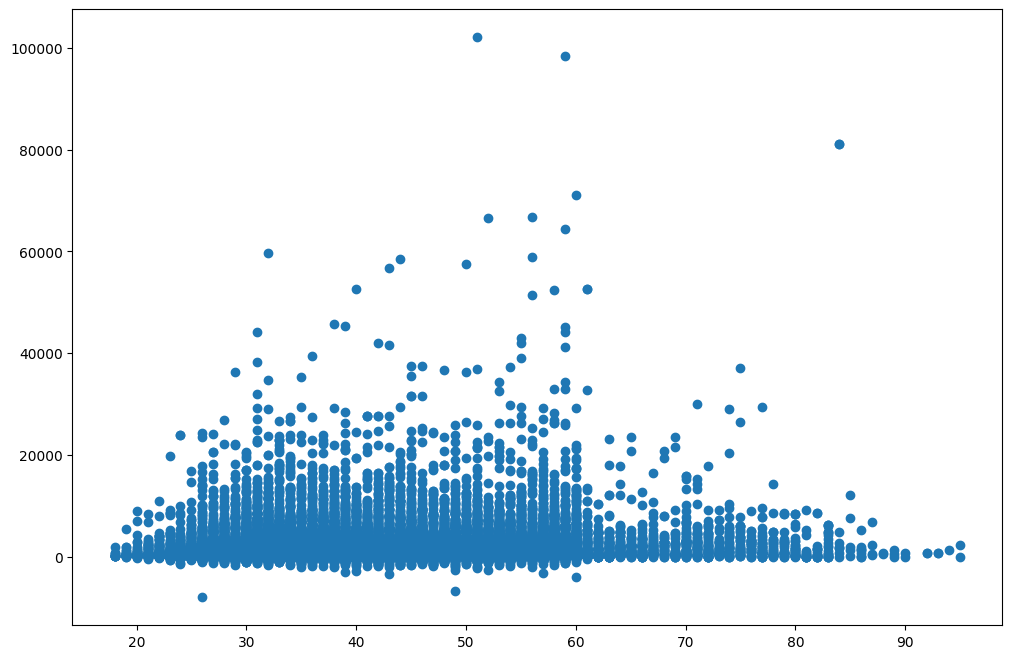

In [260]:
# buat figure scatterplot
figure = plt.subplots(figsize=(12,8))
plt.scatter(eda['age'], eda['balance'])
plt.show()

Dari visualisasi scatterplot di atas, kita dapat melihat bentuk persebaran data balance terhadap usia. Terlihat bahwa balanca lebih mungkin untuk naik ketika usia nasabah berada di usia produktif . Lalu penurunan terjadi ketika usia nasabah di atas 60 tahun yang mengimplikasikan bahwa sekitar usia tersebut banyak yang sudah pensiun.

Namun belum tentu ketika leads punya balance yang tinggi menambah potensi lebih untuk membuka deposito juga. Hal ini lebih ke menjadi acuan bagi telemarketing ketika melakukan targeting, jika ingin mentarget audience dengan balance yang tinggi maka bisa utamakan leads dengan usia produktif.

Mengingat term deposit memiliki batas minimum untuk membuka rekening, maka cara ini bisa dilakukan untuk a/b testing targeting.

In [261]:
# uji dengan spearman correlation
stat, pval = stats.spearmanr(eda['age'], eda['balance'])

# print hasil
print(stat)
print(pval)

# condition untuk menentukan intepretasi
if pval < 0.05:
    print('Korelasi signifikan')
else:
    print('Korelasi tidak signifikan')

0.096380304771986
9.361066305377314e-94
Korelasi signifikan


Berdasarkan visualisasi saja terlihat bahwa terdapat hubungan dari kedua variabel ini, maka dari itu kita melakukan uji statistik korelasi spearman untuk mengetahui hasilnya. 

Hasil p-value berada di bawah 0.05 maka berhasil menolak H0 yang dapat diartikan bahwa korelasi antara usia dan balance nyata secara statistik dan bukan hanya secara kasat mata saja.

## Feature Engineering
### Check Cardinality

In [262]:
# buat function untuk mengecek cardinality
def cek_car(df):
    '''Fungsi ini berfungsi untuk melakukan pengecekan cardinality dari kolom kategorikal dataset.'''
    # set display max width
    pd.set_option('display.max_colwidth', None)

    # define list untuk menampung data
    nama_kolom = []
    nunique = []
    unique = []

    # define list untuk acuan for loop
    cat_cols = list(df.select_dtypes(include='object').columns)

    # lakukan for looping
    for i in cat_cols:
        nama_kolom.append(i)
        nunique.append(df[i].nunique())
        unique.append(df[i].unique())

    # masukkan ke dataframe
    cardinality_df = pd.DataFrame({
        'Nama Kolom': nama_kolom,
        'Jumlah Unique': nunique,
        'List Unique Values': unique
    })

    # tampilkan hasil
    return cardinality_df

# panggil function
cek_car(df)

,Nama Kolom,Jumlah Unique,List Unique Values
0,job,12,"[management, technician, entrepreneur, blue-collar, unknown, retired, admin., services, self-employed, unemployed, housemaid, student]"
1,marital,3,"[married, single, divorced]"
2,education,4,"[tertiary, secondary, unknown, primary]"
3,default,2,"[no, yes]"
4,housing,2,"[yes, no]"
5,loan,2,"[no, yes]"
6,contact,3,"[unknown, cellular, telephone]"
7,month,12,"[may, jun, jul, aug, oct, nov, dec, jan, feb, mar, apr, sep]"
8,poutcome,4,"[unknown, failure, other, success]"
9,subscribe,2,"[no, yes]"


Karena banyaknya kolom kategoikal pada dataset ini, maka penting untuk meng-handle cardinality-nya terlebih dahulu agar model. Kolom yang perlu di-handle adalah job.

Di sini kategori job bisa dipersingkat dan dikategorisasi ulang menjadi white collar, blue collar, self employed, dan not working. 

Hal ini dapat di-handling dengan function berikut yang nantinya akan dimasukkan ke dalam pipeline model sehingga langsung di-define ke dalam function transformer. Kode di-comment agar tidak running.

In [263]:
# def cardinality(X):
#     '''Fungsi ini berguna untuk melakukan handling cardinality serta sekaligus menambah indikator untuk kolom pdays dan mengubah nilai -1'''
#     # lakukan copy agar tidak mempengaruhi data asli
#     X = X.copy()

#     # buat list untuk menampung data
#     job_list = []

#     # lakukan for looping untuk kategorisasi job
#     for i in X['job']:
#         if i in ['unemployed', 'student', 'retired']:
#             job_list.append('not_working')
#         elif i in ['admin.', 'management', 'technician']:
#             job_list.append('white_collar')
#         elif i in ['blue-collar', 'services', 'housemaid']:
#                     job_list.append('blue_collar')
#         elif i in ['entrepreneur', 'self-employed']:
#                             job_list.append('self_employed')
#         else:
#             job_list.append(i)

#     # masukkan data ke kolom job
#     X['job'] = job_list

#     # buat indikator untuk leads yang tidak dihubungi 
#     X['was_contacted'] = (X['pdays'] != -1).astype(int)

#     # ganti nilai -1 menjadi 0
#     X['pdays'] = X['pdays'].where(X['pdays'] != -1, 0) 

#     # return data baru yang sudah di-handling
#     return X

# masukkan function ke dalam transformer
feature_handling = FunctionTransformer(
    cardinality,
    validate=False, 
    check_inverse=False)

### Split Dataset
Sebelum melakukan split dataset, kita akan melakukan undersampling dikarenakan jumlah data yang sangat tidak balance antara kategori yes dan no. 

Hal ini menjadi krusial dilakukan karena ketimpangan yang ekstrim sehingga akan membuat model hanya pandai dalam memprediksi 1 kategori saja. 

Sedangkan dalam kasus ini, diperlukan model yang mampu memprediksi kedua kategori secara baik untuk menghindari terbuangnya effort dan budget karena yang diprediksi adalah leads potential palsu dan leads not potensial palsu.

In [264]:
# cek perbandingan total kedua kategori
print(df['subscribe'].value_counts())

subscribe
no     39922
yes     5289
Name: count, dtype: int64


Karena ketimpangan ekstrim ini juga metode SMOTE kurang cocok diterapkan karena nanti akan sangat banyak data sintetis sehingga data asli menjadi minoritas. Maka dari itu undersampling merupakan pilihan yang cocok dalam case ini mengingat total n minority yang masih tergolong banyak juga sehingga variasi data masih bisa tercapture. 

In [265]:
# lakukan randomize agar data tersebar
df = df.copy()
df = df.sample(frac=1, random_state=9).reset_index(drop=True)

# define jumlah minority
minority = df['subscribe'].value_counts().min()

# buat df sampling
df = df.groupby('subscribe', group_keys=False).sample(n=minority, random_state=9)
df.reset_index(drop=True)
df['subscribe'].value_counts()

subscribe
no     5289
yes    5289
Name: count, dtype: int64

Setelah data berhasil di-balance, total row data masih berada di atas 10 ribu yang mana masih bagus untuk dilakukan training. 

Maka kita bisa melakukan split data dengan rasio 80 : 20 

In [266]:
# ganti str menjadi kategori 0 1
df['subscribe'] = df['subscribe'].map({'yes':1,'no':0})

# split X dan y
X = df.drop(['subscribe'], axis=1)
y = df['subscribe']

# split X dan y menjadi train dan test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=9)
print(X_train.shape)
print(X_test.shape)

(8462, 16)
(2116, 16)


### Check Outlier

In [267]:
# define column
num_cols = list(X_train.select_dtypes(exclude='object').columns)
cat_cols = list(X_train.select_dtypes(include='object').columns)

# buat function
def skewness(X):
    '''Fungsi ini berguna untuk mengecek skewness data numerik'''

    # buat fungsi looping for untuk cek outliers
    outlier_list = []
    for i in num_cols:
        skewness = round(X[i].skew(), 2)
        label = 'normal' if -0.5 <= skewness <= 0.5 else 'skewed'

        # cek upper dan lower bound
        IQR = X[i].quantile(0.75) - X[i].quantile(0.25)
        upper = X[i].quantile(0.75) + (IQR*3)
        lower = X[i].quantile(0.25) - (IQR*3)
        percent = (len(X[X[i] < lower]) / len(X[i]) * 100) + (len(X[X[i] > upper]) / len(X[i]) * 100)

        # if agar IQR yang bernilai 0 tidak diproses
        outlier_list.append([i, skewness, label, upper, lower, percent])

    # masukkan ke dataframe
    skewness = pd.DataFrame(
        columns=['nama kolom', 'skewness', 'distribusi data', 'upper bound', 'lower bound', 'persentase outlier'],
        data=outlier_list
    )

    return skewness

# panggil function
skewness(X_train)

,nama kolom,skewness,distribusi data,upper bound,lower bound,persentase outlier
0,age,0.83,skewed,100.0,-19.00,0.000000
1,balance,8.32,skewed,6484.0,-4651.25,4.644292
2,day,0.12,normal,60.0,-31.00,0.000000
3,duration,2.11,skewed,1597.0,-949.25,1.016308
4,campaign,5.33,skewed,9.0,-5.00,2.328055
5,pdays,2.31,skewed,290.0,-219.25,6.476010
6,previous,7.57,skewed,4.0,-3.00,5.081541


Hasil pengecekan outliers di atas menunjukkan bahwa semua kolom numerik kecuali day memiliki persebaran data yang tidak normal. 

Kolom age memiliki persentase 0% meski merupakan distribusi normal artinya kolom ini tidak memiliki outlier yang ekstrim, namun masih memiliki outlier moderate. 

Maka dari itu kita akan melakukan capping dengan metode Winsorizer dengan IQR kelipatan 3 ke semua kolom numerikal sebagai bagian dari preprocessing pipeline.

Sedangkan untuk kolom duration akan kita drop karena kolom ini berisi informasi yang didapat setelah outcome target. Hal ini perlu untuk menghindari adanya data leakage. Kolom akan di-drop dalam proses pipeline dengan cara meng-exclude nya dari list kolom dalam proses preprocessing.

### Check Missing Values

In [268]:
# cek missing values
X_train.isna().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
dtype: int64

Pada pengecekan ini didapatkan bahwa dataset ini tidak memiliki missing values, namun handling missing values tetap akan dilakukan di dalam pipeline agar model inferencing tidak crash nantinya. 

Metode yang dilakukan adalah SimpleImputer dengan metode median karena mengingat kebanyakan kolom numerik memiliki distribusi yang tidak normal.

In [269]:
# cek statistik deskriptif data
X_train.describe()

,age,balance,day,duration,campaign,pdays,previous
count,8462.000000,8462.000000,8462.000000,8462.000000,8462.000000,8462.000000,8462.000000
mean,41.222288,1523.905105,15.526708,379.268849,2.488773,53.240960,0.826873
std,11.929960,3132.574795,8.401304,353.714020,2.655815,109.854369,2.203278
min,18.000000,-3372.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,32.000000,121.000000,8.000000,142.000000,1.000000,-1.000000,0.000000
50%,39.000000,548.000000,15.000000,258.000000,2.000000,-1.000000,0.000000
75%,49.000000,1711.750000,21.000000,505.750000,3.000000,71.750000,1.000000
max,95.000000,81204.000000,31.000000,3785.000000,63.000000,842.000000,58.000000


Dari informasi di atas diketahui bahwa kolom pdays memiliki nilai -1 dan akan berpotensi membuat model salah membaca arti datanya. Maka dari itu diperlukan kolom indikator untuk memberi tahu bahwa kolom tersebut leads-nya tidak dihubungi. Kemudian nilai -1 bisa kita ganti menjadi 0.

Proses ini dilakukan dengan function yang sama dengan handling cardinality dan akan dimasukkan ke dalam pipeline juga.

### Feature Selection

In [270]:
def selection(X_train):
    '''Function ini berguna untuk mengecek korelasi features terhadap target'''
    # define nilai n dan list
    n = X_train.shape[0]
    p_values = []
    intepretasi = []
    cols = []
    indicator = []

    # looping for untuk variabel numerikal
    for col in num_cols:
        coef, pval = stats.kendalltau(X_train[col], y_train)
        cols.append(col)

        if pval < 0.05:
            intepretasi.append('Ada Korelasi')
        else:
            intepretasi.append('Tidak Ada Korelasi')
            
        pval = f"{pval:.2e}"
        p_values.append(pval)

        z_score = coef/(4/(9*n)) ** 0.5
        indicator.append(f"Z-Score: {z_score}")

    # looping for untuk variabel kategorikal
    for col in cat_cols:
        contingency = pd.crosstab(X_train[col], y_train)
        stat, p, dof, ex = stats.chi2_contingency(contingency)
        cols.append(col)

        if p < 0.05:
            intepretasi.append('Ada Korelasi')
        else:
            intepretasi.append('Tidak Ada Korelasi')

        p = f"{p:.2e}"
        p_values.append(p)
        indicator.append(f"Chi Square Stat: {stat}")

    # masukkan ke dataframe
    preview = pd.DataFrame({
        'nama kolom': cols,
        'p-values': p_values,
        'intepretasi': intepretasi,
        'indikator': indicator
    })

    return preview

# call function
selection(X_train)

,nama kolom,p-values,intepretasi,indikator
0,age,4.04e-02,Ada Korelasi,Z-Score: -2.5435355754360027
1,balance,2.97e-45,Ada Korelasi,Z-Score: 17.334379683939865
2,day,4.42e-05,Ada Korelasi,Z-Score: -5.090435762564111
3,duration,0.00e+00,Ada Korelasi,Z-Score: 60.26941252580513
4,campaign,7.70e-31,Ada Korelasi,Z-Score: -15.796434813856225
5,pdays,1.91e-84,Ada Korelasi,Z-Score: 27.35007655303913
6,previous,6.14e-102,Ada Korelasi,Z-Score: 30.531986678929755
7,job,1.41e-53,Ada Korelasi,Chi Square Stat: 280.0173956682507
8,marital,9.43e-26,Ada Korelasi,Chi Square Stat: 115.24685909736212
9,education,7.44e-21,Ada Korelasi,Chi Square Stat: 96.83747769133353


Dari hasil pengujian di atas didapat bahwa semua features memiliki korelasi yang signifikan terhadap target. Maka dari itu semua features bisa dimasukkan ke dalam training model kecuali kolom duration seperti yang sudah disebutkan sebelumnya.

### Scaling and Encoding

- Metode Scaling yang digunakan adalah Standard Scaler agar variance data tetap terjaga dan lebih cocok juga untuk digunakan ke model KNN, dan SVM.
- Metode Encoding Nominal akan digunakan ke kolom 'job', 'marital', 'contact', dan 'poutcome'
- Metode Encoding Ordinal akan digunakan ke kolom 'education', 'default', 'housing', 'loan', 'month'

## Model Definition
### Preprocessing Pipeline

In [271]:
# define list
num_cols.remove('duration')
ohe_cols = ['job', 'marital', 'contact', 'poutcome']
ord_cols = ['education', 'default', 'housing', 'loan', 'month']

edu_order = ['unknown', 'primary', 'secondary', 'tertiary']
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
yes_order = ['no', 'yes']

all_order = [edu_order, yes_order, yes_order, yes_order, month_order]

# buat pipeline per kelompok variabel
num_pipeline = make_pipeline(Winsorizer(capping_method='iqr', tail='both', fold=3, missing_values='ignore', variables=[col for col in num_cols if col not in ['pdays', 'previous']]),
                              SimpleImputer(strategy='median'),
                              StandardScaler())

ohe_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'),
                              OneHotEncoder(handle_unknown='ignore', drop='first'))

ord_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'),
                              OrdinalEncoder(categories=all_order, handle_unknown='use_encoded_value', unknown_value=-1))

# buat preprocessing pipeline
preprossecing_pipe = ColumnTransformer(transformers=[
    ('pipe_num', num_pipeline, num_cols),
    ('pipe_ohe', ohe_pipeline, ohe_cols),
    ('pipe_ord', ord_pipeline, ord_cols),
    ('pipe_binary', 'passthrough', ['was_contacted'])
    ])


### Model Pipeline

In [272]:
knn = make_pipeline(
    feature_handling,
    preprossecing_pipe,
    KNeighborsClassifier(n_neighbors=5)
)

svm = make_pipeline(
    feature_handling,
    preprossecing_pipe,
    SVC(kernel='rbf')
)

decisiontree = make_pipeline(
    feature_handling,
    preprossecing_pipe,
    DecisionTreeClassifier(
        class_weight='balanced', 
        max_depth=10, 
        random_state=9
        )
)

randomforest = make_pipeline(
    feature_handling,
    preprossecing_pipe,
    RandomForestClassifier(
    class_weight='balanced',
    n_estimators=100,
    max_depth=10,
    random_state=9
    )   
)

xgboost = make_pipeline(
    feature_handling,
    preprossecing_pipe,
    XGBClassifier(
        n_estimators=100,
        max_depth=5,
        verbosity=0,
        random_state=9,
        eval_metric='auc',
        n_jobs=-1
)
)

## Model Training

In [273]:
knn.fit(X_train, y_train)

Pipeline(steps=[('functiontransformer',
                 FunctionTransformer(check_inverse=False,
                                     func=<function cardinality at 0x0000022EF3CAF430>)),
                ('columntransformer',
                 ColumnTransformer(transformers=[('pipe_num',
                                                  Pipeline(steps=[('winsorizer',
                                                                   Winsorizer(capping_method='iqr',
                                                                              fold=3,
                                                                              missing_values='ignore',
                                                                              tail='both',
                                                                              variables=['age',
                                                                                         'balance',
                                                                                         'day',
                                                                                         'campaign'])),
                                                                  ('sim...
                                                                                               'primary',
                                                                                               'secondary',
                                                                                               'tertiary'],
                                                                                              ['no',
                                                                                               'yes'],
                                                                                              ['no',
                                                                                               'yes'],
                                                                                              ['no',
                                                                                               'yes'],
                                                                                              ['jan',
                                                                                               'feb',
                                                                                               'mar',
                                                                                               'apr',
                                                                                               'may',
                                                                                               'jun',
                                                                                               'jul',
                                                                                               'aug',
                                                                                               'sep',
                                                                                               'oct',
                                                                                               'nov',
                                                                                               'dec']],
                                                                                  handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['education', 'default',
                                                   'housing', 'loan',
                                                   'month']),
                                                 ('pipe_binary', 'passthrough',
                                                  ['was_contacted'])])),
                ('kneighborsclassifier

In [274]:
svm.fit(X_train, y_train)

Pipeline(steps=[('functiontransformer',
                 FunctionTransformer(check_inverse=False,
                                     func=<function cardinality at 0x0000022EF3CAF430>)),
                ('columntransformer',
                 ColumnTransformer(transformers=[('pipe_num',
                                                  Pipeline(steps=[('winsorizer',
                                                                   Winsorizer(capping_method='iqr',
                                                                              fold=3,
                                                                              missing_values='ignore',
                                                                              tail='both',
                                                                              variables=['age',
                                                                                         'balance',
                                                                                         'day',
                                                                                         'campaign'])),
                                                                  ('sim...
                                                                   OrdinalEncoder(categories=[['unknown',
                                                                                               'primary',
                                                                                               'secondary',
                                                                                               'tertiary'],
                                                                                              ['no',
                                                                                               'yes'],
                                                                                              ['no',
                                                                                               'yes'],
                                                                                              ['no',
                                                                                               'yes'],
                                                                                              ['jan',
                                                                                               'feb',
                                                                                               'mar',
                                                                                               'apr',
                                                                                               'may',
                                                                                               'jun',
                                                                                               'jul',
                                                                                               'aug',
                                                                                               'sep',
                                                                                               'oct',
                                                                                               'nov',
                                                                                               'dec']],
                                                                                  handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['education', 'default',
                                                   'housing', 'loan',
                                                   'month']),
                                                 ('pipe_binary', 'passthrough',
     

In [275]:
decisiontree.fit(X_train, y_train)

Pipeline(steps=[('functiontransformer',
                 FunctionTransformer(check_inverse=False,
                                     func=<function cardinality at 0x0000022EF3CAF430>)),
                ('columntransformer',
                 ColumnTransformer(transformers=[('pipe_num',
                                                  Pipeline(steps=[('winsorizer',
                                                                   Winsorizer(capping_method='iqr',
                                                                              fold=3,
                                                                              missing_values='ignore',
                                                                              tail='both',
                                                                              variables=['age',
                                                                                         'balance',
                                                                                         'day',
                                                                                         'campaign'])),
                                                                  ('sim...
                                                                                               'yes'],
                                                                                              ['no',
                                                                                               'yes'],
                                                                                              ['jan',
                                                                                               'feb',
                                                                                               'mar',
                                                                                               'apr',
                                                                                               'may',
                                                                                               'jun',
                                                                                               'jul',
                                                                                               'aug',
                                                                                               'sep',
                                                                                               'oct',
                                                                                               'nov',
                                                                                               'dec']],
                                                                                  handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['education', 'default',
                                                   'housing', 'loan',
                                                   'month']),
                                                 ('pipe_binary', 'passthrough',
                                                  ['was_contacted'])])),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(class_weight='balanced', max_depth=10,
                                        random_state=9))])

In [276]:
randomforest.fit(X_train, y_train)

Pipeline(steps=[('functiontransformer',
                 FunctionTransformer(check_inverse=False,
                                     func=<function cardinality at 0x0000022EF3CAF430>)),
                ('columntransformer',
                 ColumnTransformer(transformers=[('pipe_num',
                                                  Pipeline(steps=[('winsorizer',
                                                                   Winsorizer(capping_method='iqr',
                                                                              fold=3,
                                                                              missing_values='ignore',
                                                                              tail='both',
                                                                              variables=['age',
                                                                                         'balance',
                                                                                         'day',
                                                                                         'campaign'])),
                                                                  ('sim...
                                                                                               'yes'],
                                                                                              ['no',
                                                                                               'yes'],
                                                                                              ['jan',
                                                                                               'feb',
                                                                                               'mar',
                                                                                               'apr',
                                                                                               'may',
                                                                                               'jun',
                                                                                               'jul',
                                                                                               'aug',
                                                                                               'sep',
                                                                                               'oct',
                                                                                               'nov',
                                                                                               'dec']],
                                                                                  handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['education', 'default',
                                                   'housing', 'loan',
                                                   'month']),
                                                 ('pipe_binary', 'passthrough',
                                                  ['was_contacted'])])),
                ('randomforestclassifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=10,
                                        random_state=9))])

In [277]:
xgboost.fit(X_train, y_train)

Pipeline(steps=[('functiontransformer',
                 FunctionTransformer(check_inverse=False,
                                     func=<function cardinality at 0x0000022EF3CAF430>)),
                ('columntransformer',
                 ColumnTransformer(transformers=[('pipe_num',
                                                  Pipeline(steps=[('winsorizer',
                                                                   Winsorizer(capping_method='iqr',
                                                                              fold=3,
                                                                              missing_values='ignore',
                                                                              tail='both',
                                                                              variables=['age',
                                                                                         'balance',
                                                                                         'day',
                                                                                         'campaign'])),
                                                                  ('sim...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=-1,
                               num_parallel_tree=None, random_state=9, ...))])

## Model Evaluation

In [278]:
# buat function untuk evaluasi
def evaluation(name, estimator):
    '''Fungsi ini berguna untuk melakukan evaluasi CV dan ROC AUC'''

    # define cv function
    cv_score = cross_val_score(
        estimator = estimator,
        X = X_train,
        y = y_train,
        cv = 5,
        scoring='f1'
    )

    # lakukan predict
    y_pred_test = estimator.predict(X_train)
    y_pred_test = estimator.predict(X_test)

    # masukkan ke dalam dictionary
    return {
        'model': name,
        'f1_score': f1_score(y_test, y_pred_test),
        'cv_f1_mean': cv_score.mean(),
        'cv_f1_std': cv_score.std(),
        'precision': precision_score(y_test, y_pred_test),
        'recall': recall_score(y_test, y_pred_test),
        'ROC-AUC': roc_auc_score(y_test, y_pred_test)
    }

In [279]:
# panggil function dan masukkan ke dalam list
eval_result = []
eval_result.append(evaluation('KNN', knn))
eval_result.append(evaluation('SVM', svm))
eval_result.append(evaluation('Decision Tree', decisiontree))
eval_result.append(evaluation('Random Forest', randomforest))
eval_result.append(evaluation('XGBoost', xgboost))

# masukkan ke dataframe
eval_df = pd.DataFrame(eval_result)
eval_df

,model,f1_score,cv_f1_mean,cv_f1_std,precision,recall,ROC-AUC
0,KNN,0.668949,0.655428,0.009763,0.711019,0.631579,0.681230
1,SVM,0.691646,0.679806,0.018418,0.765695,0.630656,0.714166
2,Decision Tree,0.670414,0.660426,0.016822,0.750572,0.605725,0.697345
3,Random Forest,0.706002,0.693734,0.014696,0.785957,0.640813,0.728925
4,XGBoost,0.709109,0.700220,0.008395,0.754953,0.668513,0.720510


In [280]:
# predict y train dan test
y_pred_train = xgboost.predict(X_train)
y_pred_test = xgboost.predict(X_test)

#evaluasi model classifier
print(classification_report(y_train, y_pred_train))
print()
print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.80      0.90      0.85      4256
           1       0.88      0.78      0.83      4206

    accuracy                           0.84      8462
   macro avg       0.84      0.84      0.84      8462
weighted avg       0.84      0.84      0.84      8462


              precision    recall  f1-score   support

           0       0.69      0.77      0.73      1033
           1       0.75      0.67      0.71      1083

    accuracy                           0.72      2116
   macro avg       0.72      0.72      0.72      2116
weighted avg       0.72      0.72      0.72      2116



Dari hasil evaluasi di atas didapat bahwa overall score paling bagus ada pada model XGBoost. 

Score yang perlu kita lihat pada evaluasi ini adlaah score f1 karena false negative dan false positive sama-sama merugikan bagi tim telemarketing.

- False positif atau false potential leads membuat effort dan budget terbuang sia-sia ke leads yang tidak potential. 
- False negative atau false non-potential leads membuat tim telemarketing kehilangan leads potential karena model memprediksinya sebagai not potential.

Model XGBoost memiliki nilai f1, dan recall yang terbaik. Untuk skor precision meskipun masih lebih tinggi RandomForest, namun angka 0.75 masih tergolong tinggi juga. Skor f1 tervalidasi juga dari proses cross validation dengan nilai Standard Deviation yang sangat rendah.

Dilihat dari skor ROC AUC juga XGBoost terbaik kedua dengan skor yang selisih tipis dengan RandomForest yaitu sebesar 0.72 yang artinya model ini sudah bisa membedakan kategori dengan lumayan baik.

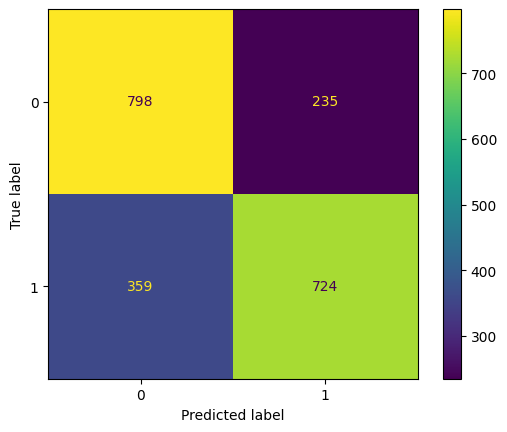

In [281]:
# buat plot confusion matrix
cm = confusion_matrix(y_test, y_pred_test)
ConfusionMatrixDisplay(cm).plot()

Sedangkan jika dilihat dari Confusion Matrix, dapat dilihat juga bahwa model ini memprediksi false negative dan false positive dengan rasio yang kurang lebih sama.

Maka dari itu kita akan melakukan Hyperparameter Tuning untuk model XGBoost untuk melihat apakah jumlah false negative dan positive bisa ditekan.

## Hyperparameter Tuning

Pada proses hyperparameter tuning ini kita akan menguji beberapa parameter penting dari algoritma XGBoost. Berikut parameter yang akan diujikan ke dalam Random Search:
- n_estimators - Berguna untuk menentukan jumlah tree yang dibuat secara sekuensial
- max_depth - Mengontrol kedalaman maksimum tiap tree model
- learning_rate - Mengatur seberapa besar kontribusi tiap tree model
- gamma - Parameter regularisasi yang menentukan minimum loss reduction yang dibutuhkan agar suatu node bisa displit lebih lanjut
- subsample - Mengontrol proporsi data baris yang digunakan secara acak
- colsample_bytree - Mengatur proporsi features yang dipilih secara acak
- scale_pos_weight - Menyeimbangkan bobot antara kelas positif dan negatif

In [282]:
# define parameter
xgb_params = {
    'xgbclassifier__n_estimators': [50, 100],
    'xgbclassifier__max_depth': [5, 10],
    'xgbclassifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'xgbclassifier__gamma': [0, 0.1, 0.2, 0.5],
    'xgbclassifier__subsample': [0.6, 0.8, 1.0],
    'xgbclassifier__colsample_bytree': [0.6, 0.8, 1.0],
    'xgbclassifier__scale_pos_weight': [1]
}

In [283]:
# define randomsearchCV
xg_randomsearch = RandomizedSearchCV(
    estimator = xgboost,
    param_distributions = xgb_params,
    n_iter = 50,
    cv = 5,
    random_state = 9,
    scoring = 'f1',
    n_jobs=-1
)


In [284]:
# lakukan training
xg_randomsearch.fit(X_train, y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('functiontransformer',
                                              FunctionTransformer(check_inverse=False,
                                                                  func=<function cardinality at 0x0000022EF3CAF430>)),
                                             ('columntransformer',
                                              ColumnTransformer(transformers=[('pipe_num',
                                                                               Pipeline(steps=[('winsorizer',
                                                                                                Winsorizer(capping_method='iqr',
                                                                                                           fold=3,
                                                                                                           missing_values='ignore',
                                                                                                           tail='both',
                                                                                                           variables=['age',
                                                                                                                      '...
                   n_iter=50, n_jobs=-1,
                   param_distributions={'xgbclassifier__colsample_bytree': [0.6,
                                                                            0.8,
                                                                            1.0],
                                        'xgbclassifier__gamma': [0, 0.1, 0.2,
                                                                 0.5],
                                        'xgbclassifier__learning_rate': [0.01,
                                                                         0.05,
                                                                         0.1,
                                                                         0.2],
                                        'xgbclassifier__max_depth': [5, 10],
                                        'xgbclassifier__n_estimators': [50,
                                                                        100],
                                        'xgbclassifier__scale_pos_weight': [1],
                                        'xgbclassifier__subsample': [0.6, 0.8,
                                                                     1.0]},
                   random_state=9, scoring='f1')

In [285]:
# panggil best parameter
xg_randomsearch.best_params_

{'xgbclassifier__subsample': 1.0,
 'xgbclassifier__scale_pos_weight': 1,
 'xgbclassifier__n_estimators': 100,
 'xgbclassifier__max_depth': 5,
 'xgbclassifier__learning_rate': 0.1,
 'xgbclassifier__gamma': 0.1,
 'xgbclassifier__colsample_bytree': 1.0}

In [286]:
# define best model
best_model = xg_randomsearch.best_estimator_

# panggil function evaluation
rs_eval_result = []
rs_eval_result.append(evaluation('XGBoost', best_model))

# tampilkan hasil evaluasi
rs_eval_df = pd.DataFrame(rs_eval_result)
rs_eval_df

,model,f1_score,cv_f1_mean,cv_f1_std,precision,recall,ROC-AUC
0,XGBoost,0.718182,0.710747,0.00565,0.792642,0.65651,0.738226


In [287]:
# predict y train dan test
y_pred_train_2 = best_model.predict(X_train)
y_pred_test_2 = best_model.predict(X_test)

#evaluasi model classifier
print(classification_report(y_train, y_pred_train_2))
print()
print(classification_report(y_test, y_pred_test_2))

              precision    recall  f1-score   support

           0       0.73      0.86      0.79      4256
           1       0.83      0.68      0.75      4206

    accuracy                           0.77      8462
   macro avg       0.78      0.77      0.77      8462
weighted avg       0.78      0.77      0.77      8462


              precision    recall  f1-score   support

           0       0.69      0.82      0.75      1033
           1       0.79      0.66      0.72      1083

    accuracy                           0.74      2116
   macro avg       0.74      0.74      0.74      2116
weighted avg       0.74      0.74      0.73      2116



Dari hasil evaluasi di atas didapat parameter dan model terbaik dari XGBoost dengan beberapa peningkatan skor

- Untuk fokus utama kita, yaitu f1 score mengalami peningkatan dari 0.70 menjadi 0.71.
- Untuk skor precision juga mengalami peningkatan yang lumayan tinggi dari 0.75 menjadi 0.79.
- Nilai recall mengalami sedikit penurunan dari 0.66 menjadi 0.65.
- Nilai ROC-AUC mengalami peningkatan dari 0.72 menjadi 0.73

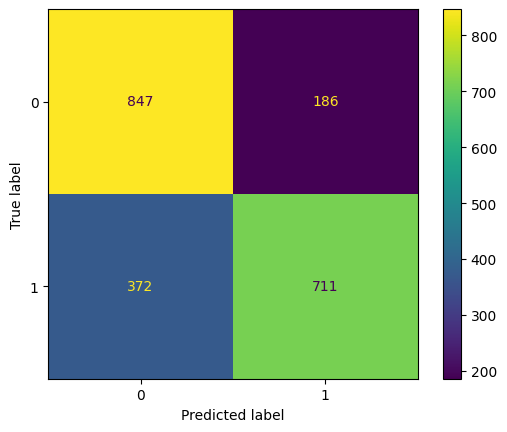

In [288]:
# buat plot confusion matrix
cm2 = confusion_matrix(y_test, y_pred_test_2)
ConfusionMatrixDisplay(cm2).plot()

Dari Confusion Matrix juga dapat dilihat bahwa jumlah prediksi false positive-nya berhasil ditekan dari yang sebelumnya 235 menjadi 186 saja. Sedangkan prediksi false negativenya mengalami sedikit kenaikan dari 359 menjadi 372. Penurunan ini masih bisa diterima sebagai cost untuk improvement yang signifikan pada score precision model.

Secara nilai overall score-nya model ini sudah lebih baik dibandingkan model sebelumnya, maka dari itu kita akan memilih model ini untuk proses prediction.

## Model Saving

In [289]:
# save best model
pickle.dump(best_model, open('pipeline.pkl', 'wb'))

## Conclusion

Berdasarkan hasil dari training dan hyperparameter tuning, didapatkan model terbaik yaitu XGBoost. Model terbaik ini sudah bisa melakukan deteksi yang seimbang antara precision dan recall. Terlihat dari skor f1 yang baik. Performa ini relevan untuk kasus marketing di mana false positive dan false negative sama-sama membawa konsekuensi budget dan effort bagi perusahaan.

Kekurangan model ini ada di skor recall yang memiliki selisih sedikit dengan RandomForest. Sehingga jika dibandingkan, RandomForest dapat mendeteksi false negative dengan lebih baik.

### Rekomendasi improvement model
- Improvement bisa dilakukan dari sisi feature engineering di mana kolom yang bersifat tanggal dapat di encode menggunakan sin dan cos agar model dapat mempelajari pola tanggal dengan lebih baik mengingat tanggal merupakan bentuk data yang cyclical.
- Feature selection lebih lanjut juga bisa dilakukan mengingat jumlah features yang digunakan memang banyak dan dikhawatirkan membawa terlalu banyak noise pada model. Maka dari itu menentukan features yang benar-benar membawa impact dalam training model juga bisa membantu meningkatkan performance-nya.
- Bisa mencoba melakukan metode lain untuk mengatasi data imbalance karena terdapat risiko dari undersampling, yaitu membuang banyak pattern dari dataset aslinya. 

Ke depannya diharapkan tim telemarketing bisa mengadopsi model ini untuk melakukan filtering leads sebelum mengeksekusi campaign periode berikutnya, lalu bisa dilakukan evaluasi perbandingan conversion rate sebelum dan sesudah mengadopsi model ini. 



## Reference
- [UCI Machine Learning Repository - Bank Marketing Dataset](https://archive.ics.uci.edu/dataset/222/bank+marketing)
- [Streamlit App Deployment for Prediction](https://bank-marketing-prediction-noveliq.streamlit.app/)
- [Direct Marketing](https://www.bee.id/blog/direct-marketing/)
- [XGBoost Documentation](https://xgboost.readthedocs.io/en/stable/)